# Choose scoring settings on a synthetic-anomaly validation set (plan item 12)

**Why this notebook exists.** Notebook 05 showed that several Tier 1 scoring changes help or hurt, but every choice of a setting (the Mahalanobis dimension, the smoothing sigma, `k`, `lambda`, the gate `tau`) can only be *made* on data that is not the test split. Today only nominal validation images exist, and nominal images contain no defects, so nothing can be chosen for **detection** quality. Item 12 of `docs/METRICS_IMPROVEMENT_PLAN.md` fixes that with labelled synthetic defects.

**The synthetic set** (`scripts/build_synthetic_validation.py`, fixed seed, fingerprinted):

* Base images are the **nominal validation** images. Textures come from nominal **training** images. Official test images are never read.
* Four defects per validation image, alternating **CutPaste** scars (a jittered, rotated patch cut from elsewhere on the object) and **DRAEM-style** Perlin-noise blends of a foreign texture. Defect area is log-uniform between 0.3% and 4% of the image, and defects stay on the object. Pixels outside the mask are untouched.
* Each synthetic image has an exact pixel mask, so image AUROC, pixel AUROC and AUPRO can all be measured.

**How settings are chosen (declared below, before any number is seen)**

1. **Cross-fitting.** The clean validation images are split into 3 folds. Statistics that are *fitted* (per-position z-score, Mahalanobis covariance, gate quantiles) come from the two other folds, and the held-out fold is scored together with the synthetic defects made from its images. The same validation image is therefore never both used for fitting and evaluated.
2. **Greedy sequential selection**, in a fixed order: score family, smoothing `sigma`, image-score `k`, fusion `lambda`, gate `tau`. At each stage every option is scored with the earlier stages' winners fixed.
3. **One criterion**: `J` = mean over the three categories of the average of image AUROC (top-`k` score), pixel AUROC and AUPRO.
4. **One global choice** for all categories (per-category winners are reported to show how consistent it is). Options within `TIE_MARGIN` of the best score are tied, and the earliest option in the declared list wins, which prefers the simpler one.

**What this notebook does not do.** It does not score the test split to choose anything. It reads the saved test numbers from notebook 05 *after* the selection is written, only to check whether the synthetic proxy ranks the variants like the real test set does. Applying the selected settings to the test split once, with a paired bootstrap, is the next step. Layer and block size (the other two knobs named in item 12) need new caches or predictors and are not covered here, apart from a capsule check of the 2x2-block predictor.

## 1. Imports and configuration

In [1]:
import json
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from PIL import Image, ImageFilter

try:
    display
except NameError:
    display = print

candidates = (Path.cwd(), *Path.cwd().parents)
PROJECT_ROOT = next((p for p in candidates if (p / 'configs').is_dir() and (p / 'src').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from the repository or its notebooks directory.')
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

CATEGORIES = ('bottle', 'capsule', 'hazelnut')
BASELINE_CHECKPOINTS = PROJECT_ROOT / 'checkpoints' / 'predictors'
BLOCK2_PATH = PROJECT_ROOT / 'checkpoints' / 'predictors_block2' / 'capsule_cosine.pt'
ENCODER_CHECKPOINT = PROJECT_ROOT / 'checkpoints' / 'IN22K-vit.g.16-600e.pth.tar'
CACHE_ROOT = PROJECT_ROOT / 'data' / 'cache' / 'latents'
SYNTHETIC_IMAGE_ROOT = PROJECT_ROOT / 'data' / 'synthetic_val'
SYNTHETIC_CACHE_ROOT = PROJECT_ROOT / 'data' / 'cache' / 'synthetic_val'
TIER1_RESULTS = PROJECT_ROOT / 'results' / 'improvements' / 'tier1'
OUTPUT_ROOT = Path(os.environ.get('SYNTHETIC_OUTPUT', PROJECT_ROOT / 'results' / 'improvements' / 'synthetic_val'))
FIGURE_ROOT = OUTPUT_ROOT / 'figures'
OVERWRITE = False
OUTPUT_FILES = ('settings_grid.csv', 'selected_settings.json', 'proxy_validity.csv', 'capsule_predictor_check.csv', 'synthetic_set_summary.json')

MASKING_CONFIG_PATH = PROJECT_ROOT / 'configs' / 'masking' / 'coarse_to_fine.yaml'
DATA_CONFIG = yaml.safe_load((PROJECT_ROOT / 'configs' / 'data' / 'mvtec.yaml').read_text(encoding='utf-8'))
VAL_FRACTION = float(DATA_CONFIG['nominal_split']['val_fraction'])
SPLIT_SEED = int(DATA_CONFIG['nominal_split']['seed'])
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# ---- Declared before any result is seen ---------------------------------------------
SYNTHETIC_SEED = 0
ANOMALIES_PER_IMAGE = 4
N_FOLDS = 3                                   # cross-fitting folds over the clean validation images
FAMILIES = (                                  # stage 1: per-token score; simplest first
    'baseline_cosine', 'pos_zscore', 'pos_centre', 'chan_standardise', 'layer_norm',
    'maha_d32', 'maha_d64', 'maha_d128',
)
SIGMAS = (0.0, 4.0, 8.0, 16.0)                # stage 2: smoothing sigma in px of the 224 map
K_VALUES = (1, 3, 5, 10, 20)                  # stage 3: image score = mean of the k highest tokens
LAMBDAS = (1.0, 0.0, 0.5, 2.0)                # stage 4: coarse + lambda * fine (default first)
TAU_OPTIONS = ('default', 'q0.9', 'q0.95', 'q0.99', 'q0.995')   # stage 5: fine-pass gate
TAU_QUANTILES = {'q0.9': 0.90, 'q0.95': 0.95, 'q0.99': 0.99, 'q0.995': 0.995}
START = {'family': 'baseline_cosine', 'sigma': 0.0, 'k': 5, 'lam': 1.0, 'tau': 'default'}
TIE_MARGIN = 0.005
POSITION_STD_FLOOR_FRACTION = 0.5
CHANNEL_STD_EPS = 1e-6
MAHA_RIDGE = 1e-3
# ---------------------------------------------------------------------------------------

if not OVERWRITE:
    existing = [OUTPUT_ROOT / n for n in OUTPUT_FILES if (OUTPUT_ROOT / n).exists()]
    if existing:
        raise FileExistsError('Refusing to overwrite: ' + ', '.join(map(str, existing)) + ' (set OVERWRITE = True)')
print(f'Project: {PROJECT_ROOT}\nDevice: {DEVICE}\nOutputs: {OUTPUT_ROOT}')

Project: C:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD
Device: cuda
Outputs: C:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\results\improvements\synthetic_val


## 2. Splits, predictors, synthetic set and caches

The synthetic cache is accepted only if its generator fingerprint, encoder checkpoint SHA-256, preprocessing and ordered image ids all match. The clean validation latents and the training latents come from the existing caches.

In [2]:
from ijepa_ad.caching.latent_cache import compute_file_sha256
from ijepa_ad.caching.synthetic_cache import load_synthetic_cache, load_synthetic_manifest, synthetic_cache_path
from ijepa_ad.caching.cache_schema import CacheExpectations, PreprocessingSpec
from ijepa_ad.data.mvtec_dataset import validate_category_splits
from ijepa_ad.data.splits import split_nominal_train_val
from ijepa_ad.data.synthetic_anomalies import SyntheticConfig
from ijepa_ad.data.transforms import PreprocessConfig
from ijepa_ad.evaluation.metrics import aupro, image_auroc, pixel_auroc
from ijepa_ad.evaluation.runner import EMBEDDING_DIM, ENCODER_NAME, NUM_TOKENS, PATCH_SIZE
from ijepa_ad.inference import MaskedLatentScorer, load_masking_settings, load_predictor_checkpoint_with_provenance
from ijepa_ad.masking.score_maps import smooth_score_maps, upsample_patch_scores
from ijepa_ad.predictor.cache_dataset import load_cached_latent_dataset
from ijepa_ad.scoring import (
    ChannelStandardisedCosine, PositionNormaliser, cosine_discrepancy, fit_channel_stats,
    fit_mahalanobis_residual, layer_norm_cosine_discrepancy,
)

ENCODER_SHA256 = compute_file_sha256(ENCODER_CHECKPOINT)
MASKING_SETTINGS = load_masking_settings(MASKING_CONFIG_PATH)
DEFAULT_TAU = MASKING_SETTINGS['threshold']
SYNTH_CONFIG = SyntheticConfig(seed=SYNTHETIC_SEED, anomalies_per_image=ANOMALIES_PER_IMAGE)
PREPROCESSING = PreprocessConfig(image_size=int(DATA_CONFIG['preprocessing']['image_size']))
PREPROCESSING_SPEC = PreprocessingSpec.from_config(PREPROCESSING)
print('synthetic fingerprint:', SYNTH_CONFIG.fingerprint())


def expectations(category, split, samples):
    return CacheExpectations(
        category=category, split=split, encoder_name=ENCODER_NAME, checkpoint_sha256=ENCODER_SHA256,
        patch_size=PATCH_SIZE, embedding_dim=EMBEDDING_DIM, preprocessing=PREPROCESSING_SPEC,
        sample_ids=tuple(s.image_id for s in samples), num_tokens=NUM_TOKENS,
    )


def mask_at_224(path):
    mask = Image.open(path).convert('L').resize((224, 224), Image.Resampling.BOX)
    return np.asarray(mask) >= 128


DATA, PREDICTORS = {}, {}
for category in CATEGORIES:
    root = next(r for r in (PROJECT_ROOT / DATA_CONFIG['root'], PROJECT_ROOT / 'dataset', PROJECT_ROOT / 'dataset' / category)
                if (r / category / 'train').is_dir())
    train_ds, _ = validate_category_splits(root, category)     # the official test split is not used here
    nominal = split_nominal_train_val(
        train_ds.samples, val_fraction=VAL_FRACTION, seed=SPLIT_SEED,
        min_train=int(DATA_CONFIG['nominal_split']['min_train']), min_val=int(DATA_CONFIG['nominal_split']['min_val']),
    )
    val = load_cached_latent_dataset(CACHE_ROOT, expectations(category, 'val', nominal.val), samples=train_ds.samples)
    train = load_cached_latent_dataset(CACHE_ROOT, expectations(category, 'train', nominal.train), samples=train_ds.samples)
    samples = load_synthetic_manifest(SYNTHETIC_IMAGE_ROOT, SYNTH_CONFIG, category)
    synthetic_latents = load_synthetic_cache(
        synthetic_cache_path(SYNTHETIC_CACHE_ROOT, SYNTH_CONFIG, category), samples, config=SYNTH_CONFIG,
        encoder_name=ENCODER_NAME, checkpoint_sha256=ENCODER_SHA256, preprocess=PREPROCESSING,
    )
    val_ids = sorted(s.image_id for s in nominal.val)
    fold_of = {image_id: rank % N_FOLDS for rank, image_id in enumerate(val_ids)}
    order = {image_id: i for i, image_id in enumerate(val.sample_ids)}
    clean_latents = val.latents
    masks_synth = np.stack([mask_at_224(s.mask_path) for s in samples])
    if not masks_synth.reshape(len(samples), -1).any(axis=1).all():
        raise ValueError(f'{category}: a synthetic mask vanished at 224 px')
    if {s.base_image_id for s in samples} != set(val.sample_ids):
        raise ValueError(f'{category}: synthetic bases are not exactly the validation images')
    n_clean, n_synth = len(val), len(samples)
    DATA[category] = {
        'latents': torch.cat([clean_latents, synthetic_latents]).float(),
        'labels': np.r_[np.zeros(n_clean, dtype=int), np.ones(n_synth, dtype=int)],
        'masks': np.concatenate([np.zeros((n_clean, 224, 224), dtype=bool), masks_synth]),
        'fold': np.r_[[fold_of[i] for i in val.sample_ids], [fold_of[s.base_image_id] for s in samples]].astype(int),
        'n_clean': n_clean, 'train_latents': train.latents, 'samples': samples,
    }
    path = BASELINE_CHECKPOINTS / f'{category}_cosine.pt'
    PREDICTORS[category], _ = load_predictor_checkpoint_with_provenance(path, category=category, encoder_sha256=ENCODER_SHA256, device=DEVICE)
    folds = np.bincount(DATA[category]['fold'][:n_clean], minlength=N_FOLDS)
    print(f'{category}: clean val={n_clean} (folds {folds.tolist()}), synthetic={n_synth}, train latents={len(train)}')

synthetic fingerprint: 46c947cb99e1faf4
bottle: clean val=21 (folds [7, 7, 7]), synthetic=84, train latents=188
capsule: clean val=22 (folds [8, 7, 7]), synthetic=88, train latents=197
hazelnut: clean val=39 (folds [13, 13, 13]), synthetic=156, train latents=352


### Synthetic set summary

What the defects look like (size, kind) and one example per category (defect outlined in red). If defects were almost invisible, or covered large parts of the object, the proxy would not be informative.

n  median_area_pct  min_area_pct  max_area_pct  mean_attempts  fallback
category kind                                                                              
bottle   cutpaste  42             0.99          0.28          3.67           1.05         0
         perlin    42             1.21          0.30          3.96           1.19         0
capsule  cutpaste  44             1.11          0.18          3.81           1.07         0
         perlin    44             1.11          0.30          3.87           1.07         0
hazelnut cutpaste  78             0.94          0.30          3.72           1.12         0
         perlin    78             1.02          0.30          3.88           1.08         0

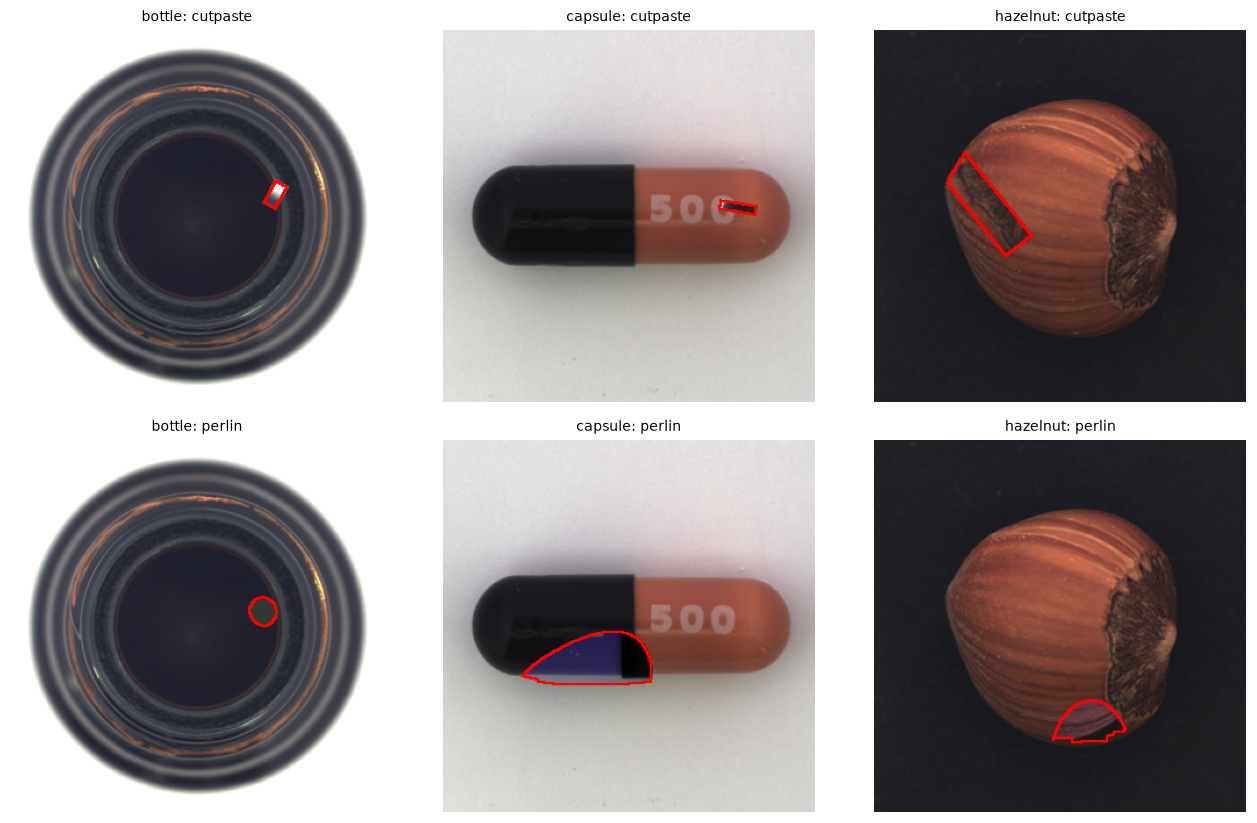

In [3]:
rows = []
for category in CATEGORIES:
    for s in DATA[category]['samples']:
        rows.append({'category': category, 'kind': s.kind, 'area_fraction': s.area_fraction, 'attempts': s.details['attempts'], 'foreground_fallback': s.details['foreground_fallback']})
synth_df = pd.DataFrame(rows)
display(synth_df.groupby(['category', 'kind']).agg(
    n=('area_fraction', 'size'), median_area_pct=('area_fraction', lambda a: 100 * a.median()),
    min_area_pct=('area_fraction', lambda a: 100 * a.min()), max_area_pct=('area_fraction', lambda a: 100 * a.max()),
    mean_attempts=('attempts', 'mean'), fallback=('foreground_fallback', 'sum')).round(2))

fig, axes = plt.subplots(2, len(CATEGORIES), figsize=(4 * len(CATEGORIES), 7.6))
for col, category in enumerate(CATEGORIES):
    for row, kind in enumerate(('cutpaste', 'perlin')):
        sample = next(s for s in DATA[category]['samples'] if s.kind == kind and s.variant >= 2)
        image = np.asarray(Image.open(sample.image_path).convert('RGB').resize((320, 320))).copy()
        mask = np.asarray(Image.open(sample.mask_path).resize((320, 320), Image.Resampling.NEAREST)) > 0
        edge = mask & ~np.asarray(Image.fromarray(mask.astype(np.uint8) * 255).filter(ImageFilter.MinFilter(5))).astype(bool)
        image[edge] = (255, 0, 0)
        axes[row, col].imshow(image); axes[row, col].set_title(f'{category}: {kind}', fontsize=9); axes[row, col].axis('off')
fig.tight_layout()
plt.show()
EXAMPLE_FIG = fig

## 3. Masked predictions, computed once

For every image (clean validation images, then their synthetic defect versions) the baseline predictor is run with the coarse (4x4) windows and with the dense single-token windows. Everything that follows (all score families, `tau`, `lambda`, `sigma`, `k`) is a function of these predictions, so no setting needs another predictor pass.

This is exact, not an approximation: a fine window masks one token, so its score does not depend on which other tokens fire the gate. The check below confirms that the post-hoc adaptive score equals what `MaskedLatentScorer` returns.

In [4]:
def masked_predictions(predictor, latents, coarse_size, dense=False):
    # dense=True: single-token (1x1) windows; the coarse size is then irrelevant
    settings = {**MASKING_SETTINGS, 'coarse_size': int(coarse_size)}
    scorer = MaskedLatentScorer(predictor, **settings)
    windows = scorer.fine.candidates() if dense else scorer.coarse.windows()
    out = torch.empty_like(latents)
    for i in range(len(latents)):
        out[i] = scorer.window_predictions(latents[i:i + 1].to(DEVICE), windows).cpu()
    return out, scorer


PRED = {}
for category in CATEGORIES:
    started = time.perf_counter()
    latents = DATA[category]['latents']
    coarse, scorer = masked_predictions(PREDICTORS[category], latents, MASKING_SETTINGS['coarse_size'])
    fine, _ = masked_predictions(PREDICTORS[category], latents, MASKING_SETTINGS['coarse_size'], dense=True)
    PRED[category] = {'coarse': coarse, 'fine': fine, 'scorer': scorer}
    print(f'{category}: {len(latents)} images, predictions in {time.perf_counter() - started:.0f}s')


def on_device(fn, predicted, actual, chunk=16):
    out = []
    for i in range(0, len(predicted), chunk):
        with torch.inference_mode():
            out.append(fn(predicted[i:i + chunk].to(DEVICE), actual[i:i + chunk].to(DEVICE)).cpu())
    return torch.cat(out)

C:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\.venv\Lib\site-packages\torch\nn\modules\transformer.py:685: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at ..\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:263.)
  return torch._transformer_encoder_layer_fwd(
bottle: 105 images, predictions in 26s
capsule: 110 images, predictions in 28s
hazelnut: 195 images, predictions in 50s


## 4. Score families, fitted by cross-fitting

Each family gives a coarse score and a dense fine score per token, for every image:

| Family | Per-token score | Fitted from |
| --- | --- | --- |
| `baseline_cosine` | `1 - cos` (the current method) | nothing |
| `pos_zscore` / `pos_centre` | baseline score, z-scored / mean-centred per token position (coarse and fine separately) | clean images of the other folds |
| `chan_standardise` | `1 - cos` after per-channel standardisation | nominal **training** latents |
| `layer_norm` | `1 - cos` after parameter-free layer norm | nothing |
| `maha_dN` | PCA-whitened residual `actual - predicted` with `N` components | clean images of the other folds |

For a held-out fold, statistics come only from the clean images of the other folds. The fine-pass gate is always evaluated on the baseline `1 - cos` region scores, as in notebook 05.

In [5]:
FAMILY_SCORES, REGION, TAU, BASE = {}, {}, {}, {}
for category in CATEGORIES:
    d = DATA[category]
    n, n_clean, fold = len(d['labels']), d['n_clean'], d['fold']
    A, Pc, Pf = d['latents'], PRED[category]['coarse'], PRED[category]['fine']
    scorer = PRED[category]['scorer']
    cos_c, cos_f = on_device(cosine_discrepancy, Pc, A), on_device(cosine_discrepancy, Pf, A)
    BASE[category] = (cos_c, cos_f)
    region = torch.zeros_like(cos_c)
    for window in scorer.coarse.windows():
        idx = list(window.token_indices)
        region[:, idx] = cos_c[:, idx].mean(dim=1, keepdim=True)
    REGION[category] = region

    chan = ChannelStandardisedCosine(fit_channel_stats(d['train_latents'], eps=CHANNEL_STD_EPS))
    families = {
        'baseline_cosine': (cos_c, cos_f),
        'chan_standardise': (on_device(chan, Pc, A), on_device(chan, Pf, A)),
        'layer_norm': (on_device(layer_norm_cosine_discrepancy, Pc, A), on_device(layer_norm_cosine_discrepancy, Pf, A)),
    }
    for name in ('pos_zscore', 'pos_centre') + tuple(f for f in FAMILIES if f.startswith('maha')):
        families[name] = (torch.zeros_like(cos_c), torch.zeros_like(cos_f))
    tau = {key: torch.zeros(n) for key in TAU_OPTIONS}
    tau['default'][:] = DEFAULT_TAU
    for f in range(N_FOLDS):
        fit = np.flatnonzero((fold != f) & (np.arange(n) < n_clean))     # clean images of the other folds
        held = np.flatnonzero(fold == f)                                  # this fold's clean + synthetic images
        for name, divide in (('pos_zscore', True), ('pos_centre', False)):
            kwargs = {'divide': divide, **({'std_floor_fraction': POSITION_STD_FLOOR_FRACTION} if divide else {})}
            norm_c, norm_f = PositionNormaliser.fit(cos_c[fit], **kwargs), PositionNormaliser.fit(cos_f[fit], **kwargs)
            families[name][0][held] = norm_c.apply(cos_c[held])
            families[name][1][held] = norm_f.apply(cos_f[held])
        residuals = (A[fit] - Pc[fit]).reshape(-1, A.shape[-1])
        for name in (f for f in FAMILIES if f.startswith('maha')):
            model = fit_mahalanobis_residual(residuals, n_components=int(name[6:]), ridge=MAHA_RIDGE)
            families[name][0][held] = on_device(model, Pc[held], A[held])
            families[name][1][held] = on_device(model, Pf[held], A[held])
        for key, q in TAU_QUANTILES.items():
            tau[key][held] = float(np.quantile(region[fit].flatten().numpy(), q))
    FAMILY_SCORES[category], TAU[category] = families, tau
    print(f'{category}: {len(families)} families fitted on {N_FOLDS} folds; example tau (fold 0) ' + ', '.join(f'{k}={tau[k][fold == 0][0]:.3f}' for k in TAU_OPTIONS))


def patch_scores(category, family, tau_key, lam):
    coarse, fine = FAMILY_SCORES[category][family]
    fired = REGION[category] >= TAU[category][tau_key][:, None]
    return coarse + lam * fired.float() * fine


# the post-hoc adaptive score must equal what the scorer returns for the baseline settings
for category in CATEGORIES:
    scorer = MaskedLatentScorer(PREDICTORS[category], **MASKING_SETTINGS)
    mine = patch_scores(category, 'baseline_cosine', 'default', MASKING_SETTINGS['lam'])
    for i in (0, DATA[category]['n_clean'], len(mine) - 1):
        reference = scorer.score(DATA[category]['latents'][i:i + 1].to(DEVICE), mode='adaptive').patch_scores.cpu()
        assert torch.allclose(mine[i], reference, atol=1e-5), (category, i, (mine[i] - reference).abs().max())
print('post-hoc adaptive scores equal MaskedLatentScorer for the baseline settings')

bottle: 8 families fitted on 3 folds; example tau (fold 0) default=0.500, q0.9=0.093, q0.95=0.122, q0.99=0.148, q0.995=0.178
capsule: 8 families fitted on 3 folds; example tau (fold 0) default=0.500, q0.9=0.205, q0.95=0.219, q0.99=0.263, q0.995=0.283
hazelnut: 8 families fitted on 3 folds; example tau (fold 0) default=0.500, q0.9=0.275, q0.95=0.309, q0.99=0.349, q0.995=0.355
post-hoc adaptive scores equal MaskedLatentScorer for the baseline settings


## 5. Evaluation function

For a configuration `(family, tau, lambda, sigma)` the function returns image AUROC for every `k`, pixel AUROC and AUPRO (the same implementations and settings as the test evaluation). Pixel metrics are measured at 224 x 224 against the defect masks reduced to that size (a pixel counts as defect when at least half of it is covered). Clean images contribute empty masks, as the good images do in the test set. Smoothed configurations read the image score at the 196 token centres, exactly as in notebook 05.

In [6]:
def centre_samples(maps224):
    return torch.nn.functional.avg_pool2d(maps224[:, :, 7:, 7:], kernel_size=2, stride=16).flatten(1)


CACHE = {}


def evaluate(category, family, tau_key, lam, sigma):
    key = (category, family, tau_key, lam, sigma)
    if key in CACHE:
        return CACHE[key]
    labels, masks = DATA[category]['labels'], list(DATA[category]['masks'])
    patch = patch_scores(category, family, tau_key, lam)
    if sigma == 0.0:
        token_scores = patch
        maps = upsample_patch_scores(patch, output_size=224)[:, 0].numpy()
    else:
        smoothed = smooth_score_maps(upsample_patch_scores(patch, output_size=224), sigma)
        token_scores = centre_samples(smoothed)
        maps = smoothed[:, 0].numpy()
    maps = list(maps.astype(np.float32))
    result = {f'image_auroc_k{k}': image_auroc(labels, token_scores.topk(k, dim=1).values.mean(dim=1).numpy()) for k in K_VALUES}
    result['pixel_auroc'] = pixel_auroc(maps, masks)
    result['aupro'] = aupro(maps, masks, num_thresholds=200)
    CACHE[key] = result
    return result


def criterion(result, k):
    return (result[f'image_auroc_k{k}'] + result['pixel_auroc'] + result['aupro']) / 3


started = time.perf_counter()
reference = {c: evaluate(c, 'baseline_cosine', 'default', 1.0, 0.0) for c in CATEGORIES}
print(f'one evaluation per category took {time.perf_counter() - started:.1f}s')
display(pd.DataFrame(reference).T.round(3))

one evaluation per category took 4.5s


,image_auroc_k1,image_auroc_k3,image_auroc_k5,image_auroc_k10,image_auroc_k20,pixel_auroc,aupro
bottle,0.787,0.830,0.834,0.821,0.817,0.950,0.828
capsule,0.558,0.657,0.710,0.735,0.743,0.878,0.610
hazelnut,0.634,0.699,0.730,0.749,0.756,0.894,0.683


**How hard is the proxy?** The baseline row above is the current method on the synthetic set. If image AUROC were about 1.0 there would be no room to tell settings apart, and if it were about 0.5 the defects would not be detectable at all. The test split's baseline (notebook 03/05) lies between the two for these categories, which is what a useful proxy needs.

## 6. Greedy sequential selection

Stages run in the declared order. For each stage, every option is evaluated with the earlier winners fixed, `J` is averaged over the three categories, and the earliest option within `TIE_MARGIN` of the best wins. All evaluations are saved, not just the winners.

In [7]:
STAGES = (('family', FAMILIES), ('sigma', SIGMAS), ('k', K_VALUES), ('lam', LAMBDAS), ('tau', TAU_OPTIONS))
grid_rows, SELECTION = [], []
current = dict(START)
for stage, options in STAGES:
    stage_rows = []
    for option in options:
        setting = {**current, stage: option}
        row = {'stage': stage, 'option': str(option)}
        per_category = {}
        for category in CATEGORIES:
            result = evaluate(category, setting['family'], setting['tau'], setting['lam'], setting['sigma'])
            per_category[category] = criterion(result, setting['k'])
            grid_rows.append({
                'stage': stage, 'option': str(option), 'category': category, **{f'cfg_{k}': v for k, v in setting.items()},
                'image_auroc_at_cfg_k': result[f'image_auroc_k{setting["k"]}'], 'pixel_auroc': result['pixel_auroc'],
                'aupro': result['aupro'], 'J': per_category[category],
                **{f'image_auroc_k{k}': result[f'image_auroc_k{k}'] for k in K_VALUES},
            })
        row.update({f'J_{c}': v for c, v in per_category.items()})
        row['J_mean'] = float(np.mean(list(per_category.values())))
        stage_rows.append(row)
    table = pd.DataFrame(stage_rows)
    best = table.J_mean.max()
    winner_index = next(i for i, r in table.iterrows() if r.J_mean >= best - TIE_MARGIN)       # earliest within the margin
    winner = options[winner_index]
    table['selected'] = [i == winner_index for i in table.index]
    per_category_best = {c: str(options[int(table[f'J_{c}'].idxmax())]) for c in CATEGORIES}
    SELECTION.append({'stage': stage, 'winner': winner if not isinstance(winner, np.generic) else winner.item(),
                      'J_mean_of_winner': float(table.J_mean[winner_index]), 'best_J_mean': float(best),
                      'tie_broken_toward_simpler': bool(table.J_mean[winner_index] < best), 'per_category_best_option': per_category_best,
                      'table': table.round(4).to_dict(orient='records')})
    current[stage] = winner
    print(f'\nstage {stage}: selected {winner!r}  (J_mean {table.J_mean[winner_index]:.4f}, best {best:.4f}); per-category best: {per_category_best}')
    display(table.round(4))
SELECTED = dict(current)
print('\nSELECTED SETTINGS (global):', SELECTED)


stage family: selected 'pos_zscore'  (J_mean 0.9245, best 0.9247); per-category best: {'bottle': 'maha_d128', 'capsule': 'pos_zscore', 'hazelnut': 'pos_zscore'}

stage sigma: selected 0.0  (J_mean 0.9245, best 0.9288); per-category best: {'bottle': '4.0', 'capsule': '4.0', 'hazelnut': '4.0'}

stage k: selected 3  (J_mean 0.9230, best 0.9251); per-category best: {'bottle': '1', 'capsule': '10', 'hazelnut': '10'}

stage lam: selected 1.0  (J_mean 0.9230, best 0.9232); per-category best: {'bottle': '0.0', 'capsule': '1.0', 'hazelnut': '1.0'}

stage tau: selected 'default'  (J_mean 0.9230, best 0.9230); per-category best: {'bottle': 'default', 'capsule': 'default', 'hazelnut': 'default'}

SELECTED SETTINGS (global): {'family': 'pos_zscore', 'sigma': 0.0, 'k': 3, 'lam': 1.0, 'tau': 'default'}


,stage,option,J_bottle,J_capsule,J_hazelnut,J_mean,selected
0,family,baseline_cosine,0.8709,0.7326,0.7694,0.7909,False
1,family,pos_zscore,0.9168,0.9643,0.8923,0.9245,True
2,family,pos_centre,0.8930,0.9020,0.8637,0.8862,False
3,family,chan_standardise,0.8136,0.6977,0.7287,0.7467,False
4,family,layer_norm,0.8709,0.7325,0.7698,0.7911,False
5,family,maha_d32,0.8531,0.7958,0.6493,0.7661,False
6,family,maha_d64,0.9072,0.9330,0.7909,0.8770,False
7,family,maha_d128,0.9280,0.9591,0.8870,0.9247,False


,stage,option,J_bottle,J_capsule,J_hazelnut,J_mean,selected
0,sigma,0.0,0.9168,0.9643,0.8923,0.9245,True
1,sigma,4.0,0.9216,0.9673,0.8975,0.9288,False
2,sigma,8.0,0.9215,0.9659,0.8968,0.9281,False
3,sigma,16.0,0.9038,0.9512,0.8714,0.9088,False


,stage,option,J_bottle,J_capsule,J_hazelnut,J_mean,selected
0,k,1,0.9174,0.9497,0.8770,0.9147,False
1,k,3,0.9162,0.9620,0.8906,0.9230,True
2,k,5,0.9168,0.9643,0.8923,0.9245,False
3,k,10,0.9162,0.9653,0.8938,0.9251,False
4,k,20,0.9136,0.9605,0.8906,0.9216,False


,stage,option,J_bottle,J_capsule,J_hazelnut,J_mean,selected
0,lam,1.0,0.9162,0.962,0.8906,0.9230,True
1,lam,0.0,0.9170,0.962,0.8906,0.9232,False
2,lam,0.5,0.9169,0.962,0.8906,0.9232,False
3,lam,2.0,0.9159,0.962,0.8906,0.9229,False


,stage,option,J_bottle,J_capsule,J_hazelnut,J_mean,selected
0,tau,default,0.9162,0.9620,0.8906,0.9230,True
1,tau,q0.9,0.9152,0.9344,0.8612,0.9036,False
2,tau,q0.95,0.9135,0.9389,0.8662,0.9062,False
3,tau,q0.99,0.9145,0.9527,0.8815,0.9162,False
4,tau,q0.995,0.9134,0.9598,0.8815,0.9183,False


### What the selection gained, on the data it was chosen on

The selected configuration against the starting configuration (the current method) on the synthetic set, per category. This is **optimistic** by construction, because the settings were chosen on these very images; it only shows how large the selected effect is on the proxy. The honest number comes from applying the selection to the test split once.

In [8]:
final_rows = []
for label, setting in (('start (current method)', START), ('selected', SELECTED)):
    for category in CATEGORIES:
        r = evaluate(category, setting['family'], setting['tau'], setting['lam'], setting['sigma'])
        final_rows.append({'config': label, 'category': category, f'image_auroc_k{setting["k"]}': r[f'image_auroc_k{setting["k"]}'],
                           'pixel_auroc': r['pixel_auroc'], 'aupro': r['aupro'], 'J': criterion(r, setting['k'])})
final_df = pd.DataFrame(final_rows)
display(final_df.round(4))

,config,category,image_auroc_k5,pixel_auroc,aupro,J,image_auroc_k3
0,start (current method),bottle,0.8345,0.9502,0.8280,0.8709,NaN
1,start (current method),capsule,0.7097,0.8779,0.6101,0.7326,NaN
2,start (current method),hazelnut,0.7304,0.8943,0.6833,0.7694,NaN
3,selected,bottle,NaN,0.9643,0.8723,0.9162,0.9121
4,selected,capsule,NaN,0.9871,0.9517,0.9620,0.9473
5,selected,hazelnut,NaN,0.9638,0.8604,0.8906,0.8476


## 7. Capsule: the 2x2-block predictor on the synthetic set

Plan item 5 on the proxy: the baseline and the 2x2-block capsule predictor, each with 4x4 and 2x2 coarse windows (baseline family, default `tau`, `lambda = 1`, `sigma = 0`, `k = 5`). It is a separate table because the block2 predictor exists only for capsule, so it cannot take part in the global selection. The checkpoint's recorded train and validation ids must equal the ones used here.

In [9]:
block2, _ = load_predictor_checkpoint_with_provenance(BLOCK2_PATH, category='capsule', encoder_sha256=ENCODER_SHA256, device=DEVICE)
payload = torch.load(BLOCK2_PATH, map_location='cpu', weights_only=True)['cache_provenance']
if set(payload['val']['sample_ids']) != {s.base_image_id for s in DATA['capsule']['samples']}:
    raise ValueError('block2 validation ids differ from the validation images used here')

capsule = DATA['capsule']
labels, masks = capsule['labels'], list(capsule['masks'])
rows = []
for predictor_name, predictor in (('baseline predictor', PREDICTORS['capsule']), ('2x2-block predictor', block2)):
    fine, _ = masked_predictions(predictor, capsule['latents'], 4, dense=True)
    for size in (4, 2):
        coarse, scorer = masked_predictions(predictor, capsule['latents'], size)
        cos_c, cos_f = on_device(cosine_discrepancy, coarse, capsule['latents']), on_device(cosine_discrepancy, fine, capsule['latents'])
        region = torch.zeros_like(cos_c)
        for window in scorer.coarse.windows():
            idx = list(window.token_indices)
            region[:, idx] = cos_c[:, idx].mean(dim=1, keepdim=True)
        patch = cos_c + 1.0 * (region >= DEFAULT_TAU).float() * cos_f
        maps = list(upsample_patch_scores(patch, output_size=224)[:, 0].numpy().astype(np.float32))
        rows.append({'predictor': predictor_name, 'coarse_window': size, 'coarse_masks': len(scorer.coarse.windows()),
                     'image_auroc_max': image_auroc(labels, patch.max(dim=1).values.numpy()),
                     'image_auroc_top5': image_auroc(labels, patch.topk(5, dim=1).values.mean(dim=1).numpy()),
                     'pixel_auroc': pixel_auroc(maps, masks), 'aupro': aupro(maps, masks, num_thresholds=200)})
capsule_df = pd.DataFrame(rows)
display(capsule_df.round(4))

,predictor,coarse_window,coarse_masks,image_auroc_max,image_auroc_top5,pixel_auroc,aupro
0,baseline predictor,4,16,0.5584,0.7097,0.8779,0.6101
1,baseline predictor,2,49,0.6178,0.7107,0.8848,0.6304
2,2x2-block predictor,4,16,0.5909,0.7040,0.8726,0.5974
3,2x2-block predictor,2,49,0.6906,0.7092,0.8809,0.6212


## 8. Save the selection

Written *before* the proxy is compared with any test number, so the check in the next section cannot influence the choice.

In [10]:
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
if not OVERWRITE:
    existing = [OUTPUT_ROOT / n for n in OUTPUT_FILES if (OUTPUT_ROOT / n).exists()] + list(FIGURE_ROOT.glob('*.png'))
    if existing:
        raise FileExistsError('Refusing to overwrite: ' + ', '.join(map(str, existing)))

pd.DataFrame(grid_rows).to_csv(OUTPUT_ROOT / 'settings_grid.csv', index=False)
capsule_df.to_csv(OUTPUT_ROOT / 'capsule_predictor_check.csv', index=False)
EXAMPLE_FIG.savefig(FIGURE_ROOT / 'synthetic_examples.png', dpi=130, bbox_inches='tight')
(OUTPUT_ROOT / 'synthetic_set_summary.json').write_text(json.dumps({
    'generator_fingerprint': SYNTH_CONFIG.fingerprint(),
    'generator_config': {k: v for k, v in SYNTH_CONFIG.__dict__.items()},
    'base_images': 'nominal validation images only', 'texture_sources': 'nominal training images only',
    'test_split_used': False, 'encoder_sha256': ENCODER_SHA256,
    'counts': {c: {'clean_validation': int(DATA[c]['n_clean']), 'synthetic': int(len(DATA[c]['samples']))} for c in CATEGORIES},
    'by_kind': synth_df.groupby(['category', 'kind']).size().unstack().to_dict(orient='index'),
}, indent=2, sort_keys=True, default=str), encoding='utf-8')
selected = {
    'declared_before_results': {
        'n_folds': N_FOLDS, 'families': list(FAMILIES), 'sigmas': list(SIGMAS), 'k_values': list(K_VALUES),
        'lambdas': list(LAMBDAS), 'tau_options': list(TAU_OPTIONS), 'start': START, 'tie_margin': TIE_MARGIN,
        'criterion': 'mean over categories of mean(image AUROC at the stage k, pixel AUROC, AUPRO)',
        'selection': 'greedy, in stage order family -> sigma -> k -> lambda -> tau; global across categories; earliest option within the tie margin',
        'position_std_floor_fraction': POSITION_STD_FLOOR_FRACTION, 'maha_ridge': MAHA_RIDGE,
    },
    'selected_settings': SELECTED,
    'stages': SELECTION,
    'chosen_from': 'synthetic-anomaly validation set (nominal validation images + synthetic defects), cross-fitted',
    'test_used_for_selection': False,
    'not_covered': 'encoder layer and mask block size (need new caches / predictors); capsule 2x2-block predictor is reported separately',
}
(OUTPUT_ROOT / 'selected_settings.json').write_text(json.dumps(selected, indent=2, sort_keys=True, default=str), encoding='utf-8')
print('selection saved:', SELECTED)

selection saved: {'family': 'pos_zscore', 'sigma': 0.0, 'k': 3, 'lam': 1.0, 'tau': 'default'}


## 9. Does the proxy rank variants like the real test split?

A proxy is only useful if its ranking carries over. The stage-1 families are the Tier 1 variants of notebook 05 (same default `tau`, `lambda = 1`, `sigma = 0`), so their synthetic-validation metrics can be set beside the saved test metrics. The comparison is a **diagnostic after the fact**: the selection above is already saved and does not depend on it. A weak correlation would mean the synthetic defects are a poor stand-in and the selected settings should not be trusted.

Spearman rank correlation is computed within each category over the 8 families (pooling categories would mostly measure the difference between categories).

In [11]:
mapping = {
    'baseline_cosine': 'baseline', 'pos_zscore': '1a_position_zscore', 'pos_centre': '1b_position_centre_only',
    'chan_standardise': '2a_channel_standardise', 'layer_norm': '2b_layer_norm',
    'maha_d32': '4_mahalanobis_d32', 'maha_d64': '4_mahalanobis_d64', 'maha_d128': '4_mahalanobis_d128',
}
test = pd.read_csv(TIER1_RESULTS / 'variant_metrics.csv')
proxy_rows = []
for category in CATEGORIES:
    for family, name in mapping.items():
        r = evaluate(category, family, 'default', 1.0, 0.0)
        t = test[(test.category == category) & (test.variant == name)].iloc[0]
        proxy_rows.append({
            'category': category, 'family': family,
            'synthetic_image_auroc_max': r['image_auroc_k1'], 'test_image_auroc_max': t.image_auroc_max,
            'synthetic_image_auroc_top5': r['image_auroc_k5'], 'test_image_auroc_top5': t.image_auroc_top5,
            'synthetic_pixel_auroc': r['pixel_auroc'], 'test_pixel_auroc': t.pixel_auroc,
            'synthetic_aupro': r['aupro'], 'test_aupro': t.aupro,
        })
proxy_df = pd.DataFrame(proxy_rows)
corr_rows = []
for category in CATEGORIES:
    view = proxy_df[proxy_df.category == category]
    row = {'category': category}
    for metric in ('image_auroc_max', 'image_auroc_top5', 'pixel_auroc', 'aupro'):
        row[metric] = view[f'synthetic_{metric}'].rank().corr(view[f'test_{metric}'].rank())
    corr_rows.append(row)
corr_df = pd.DataFrame(corr_rows).set_index('category')
corr_df.loc['mean over categories'] = corr_df.mean()
display(corr_df.round(3))
display(proxy_df.round(3))

,image_auroc_max,image_auroc_top5,pixel_auroc,aupro
category,,,,
bottle,0.970,0.855,0.857,0.976
capsule,0.422,0.898,0.810,0.881
hazelnut,0.826,0.833,0.857,0.952
mean over categories,0.739,0.862,0.841,0.937


,category,family,synthetic_image_auroc_max,test_image_auroc_max,synthetic_image_auroc_top5,test_image_auroc_top5,synthetic_pixel_auroc,test_pixel_auroc,synthetic_aupro,test_aupro
0,bottle,baseline_cosine,0.787,0.925,0.834,0.956,0.950,0.930,0.828,0.766
1,bottle,pos_zscore,0.916,0.993,0.914,0.998,0.964,0.952,0.872,0.831
2,bottle,pos_centre,0.867,0.930,0.863,0.979,0.957,0.950,0.859,0.817
3,bottle,chan_standardise,0.655,0.771,0.776,0.937,0.917,0.869,0.748,0.552
4,bottle,layer_norm,0.787,0.925,0.834,0.956,0.950,0.930,0.828,0.766
5,bottle,maha_d32,0.771,0.898,0.855,0.953,0.918,0.866,0.787,0.693
6,bottle,maha_d64,0.926,0.979,0.939,0.990,0.943,0.943,0.840,0.815
7,bottle,maha_d128,0.938,0.997,0.948,0.995,0.963,0.964,0.872,0.847
8,capsule,baseline_cosine,0.558,0.522,0.710,0.528,0.878,0.684,0.610,0.098
9,capsule,pos_zscore,0.910,0.622,0.954,0.690,0.987,0.901,0.952,0.508


In [12]:
proxy_df.to_csv(OUTPUT_ROOT / 'proxy_validity.csv', index=False)
corr_df.to_csv(OUTPUT_ROOT / 'proxy_validity_spearman.csv')
saved = json.loads((OUTPUT_ROOT / 'selected_settings.json').read_text(encoding='utf-8'))
saved['proxy_validity_spearman_vs_notebook05_test'] = corr_df.round(4).to_dict(orient='index')
saved['proxy_validity_note'] = 'computed after the selection was saved; diagnostic only'
(OUTPUT_ROOT / 'selected_settings.json').write_text(json.dumps(saved, indent=2, sort_keys=True, default=str), encoding='utf-8')
print('saved proxy validity')

saved proxy validity


## What you can and cannot say

**You can say**

* The synthetic set is built only from nominal validation and training images with a fixed seed (the fingerprint is recorded), so settings chosen on it did not touch the test split.
* The selected settings, the full grid behind them, and which option each category preferred (the more categories agree, the more transferable the choice).
* How well the proxy ranked the Tier 1 variants against the real test split (Spearman table), computed after the selection.

**You cannot say**

* That the selected settings improve the test split. That is measured by applying them once to the test split with a paired bootstrap.
* That the synthetic gain shown above is a real gain: it is measured on the data the settings were chosen on.
* That CutPaste and Perlin defects look like MVTec defects. They are a controlled stand-in; a low proxy correlation would say they are not a good one.
* Anything about encoder layer or block size, which this notebook does not search.